In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
import pandas as pd
from io import StringIO

data = """name,age,country,gender,income
John,29,USA,Male,55000
Jane,32,Canada,Female,62000
Alex,25,USA,Male,47000
Maria,34,Spain,Female,72000
Li,27,China,Male,51000
Asha,30,India,Female,68000
Ahmed,38,India,Male,68000
Rachel,29,USA,Female,62000
Carlos,41,Mexico,Male,45000
Emily,31,USA,Female,58000
Priya,28,India,Female,65000
David,45,Canada,Male,150000      
"""

df = pd.read_csv(StringIO(data))

# Save dataset
df.to_csv("people_income_data.csv", index=False)

print("Dataset created successfully!")

Dataset created successfully!


In [14]:
df.head

<bound method NDFrame.head of       name  age country  gender  income
0     John   29     USA    Male   55000
1     Jane   32  Canada  Female   62000
2     Alex   25     USA    Male   47000
3    Maria   34   Spain  Female   72000
4       Li   27   China    Male   51000
5     Asha   30   India  Female   68000
6    Ahmed   38   India    Male   68000
7   Rachel   29     USA  Female   62000
8   Carlos   41  Mexico    Male   45000
9    Emily   31     USA  Female   58000
10   Priya   28   India  Female   65000
11   David   45  Canada    Male  150000>

In [15]:
df.shape

(12, 5)

In [16]:
df.columns

Index(['name', 'age', 'country', 'gender', 'income'], dtype='str')

In [17]:
df.dtypes

name         str
age        int64
country      str
gender       str
income     int64
dtype: object

In [18]:
df.isnull().sum()

name       0
age        0
country    0
gender     0
income     0
dtype: int64

In [19]:
df.describe()

,age,income
count,12.000000,12.000000
mean,32.416667,66916.666667
std,6.037133,27526.708793
min,25.000000,45000.000000
25%,28.750000,54000.000000
50%,30.500000,62000.000000
75%,35.000000,68000.000000
max,45.000000,150000.000000


In [20]:
df["country"].value_counts()

country
USA       4
India     3
Canada    2
Spain     1
China     1
Mexico    1
Name: count, dtype: int64

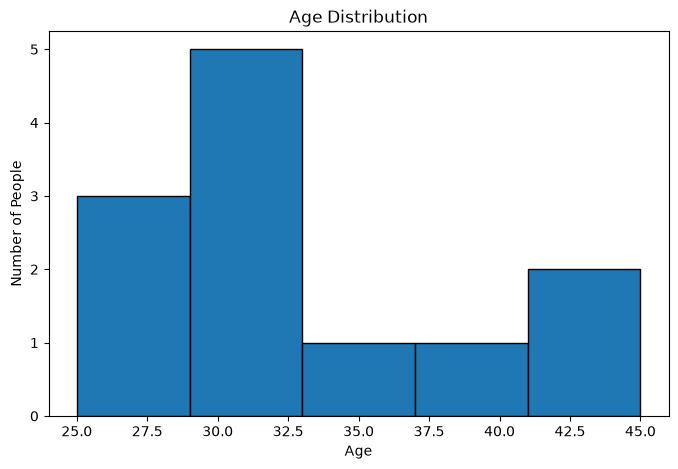

In [21]:
# Creating Histogram 
plt.figure(figsize=(8, 5))

plt.hist(
    df["age"],
    bins=5,
    edgecolor="black"
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of People")

plt.show()

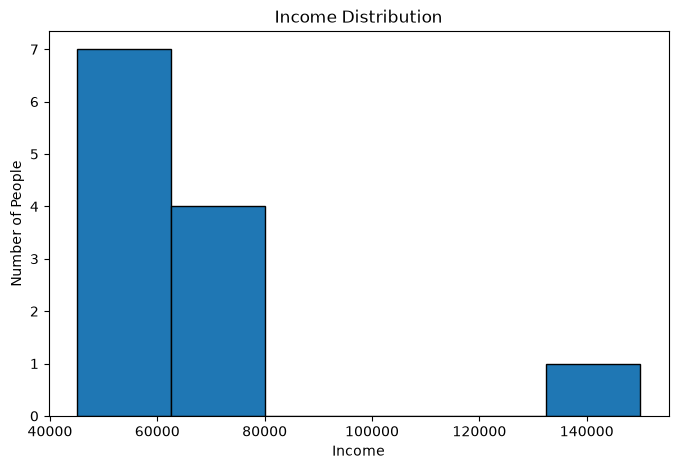

In [22]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["income"],
    bins=6,
    edgecolor="black"
)

plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Number of People")

plt.show()

In [24]:
country_income = df.groupby("country")["income"].mean()

print(country_income)

country
Canada    106000.0
China      51000.0
India      67000.0
Mexico     45000.0
Spain      72000.0
USA        55500.0
Name: income, dtype: float64


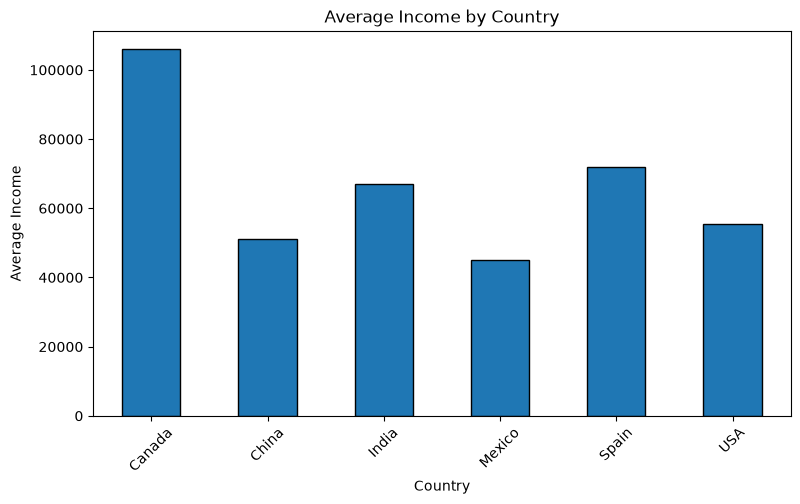

In [25]:
# Creating Bar Chart
plt.figure(figsize=(9, 5))

country_income.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Income by Country")
plt.xlabel("Country")
plt.ylabel("Average Income")

plt.xticks(rotation=45)

plt.show()

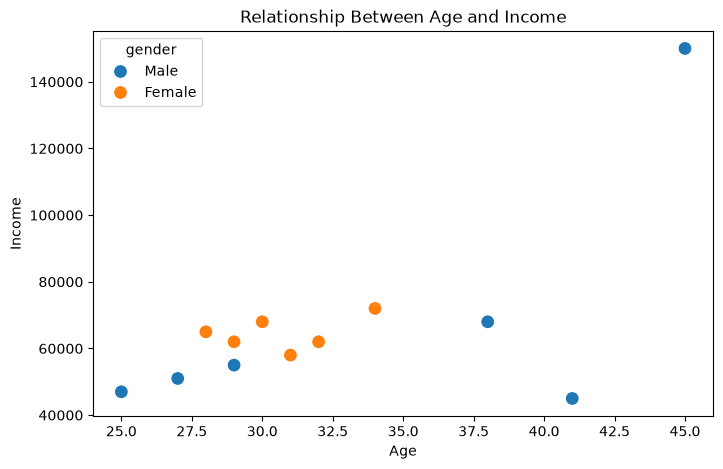

In [28]:
# Creating ScatterPlot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="income",
    hue="gender",
    s=100
)

plt.title("Relationship Between Age and Income")
plt.xlabel("Age")
plt.ylabel("Income")

plt.show()

In [30]:
# Finding Outlier with using IQR
Q1 = df["income"].quantile(0.25)

Q3 = df["income"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: 33000.0
Upper Limit: 89000.0


In [31]:
outliers = df[
    (df["income"] < lower_limit) |
    (df["income"] > upper_limit)
]

print(outliers)

     name  age country gender  income
11  David   45  Canada   Male  150000


## Complete Summary with using EDA

In [32]:
# Complete summary
print("EDA SUMMARY")
print("========================")

print("Total records:", len(df))

print("Average Age:", round(df["age"].mean(), 2))

print("Average Income:", round(df["income"].mean(), 2))

print("Highest Income:", df["income"].max())

print("Lowest Income:", df["income"].min())

print("\nPeople by Country:")
print(df["country"].value_counts())

print("\nPeople by Gender:")
print(df["gender"].value_counts())

print("\nIncome Outliers:")
print(len(outliers))

EDA SUMMARY
Total records: 12
Average Age: 32.42
Average Income: 66916.67
Highest Income: 150000
Lowest Income: 45000

People by Country:
country
USA       4
India     3
Canada    2
Spain     1
China     1
Mexico    1
Name: count, dtype: int64

People by Gender:
gender
Male      6
Female    6
Name: count, dtype: int64

Income Outliers:
1
